In [ ]:
#pip install lime 
# #to install lime I had to use python 3.12 venv and then pip install lime: py -3.12 -m venv .venv && .venv\Scripts\Activate.ps1 && pip install lime


SyntaxError: invalid syntax (1338756171.py, line 1)

In [ ]:
# Import the necessary libraries
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Import the model and the data
from models import build_model
from data import get_datasets, get_loaders


In [ ]:
# Example: CNN model
loaders = get_loaders(batch_size=128, p=0.9)

train_loader = loaders["train_biased"]
test_loader  = loaders["test_conflicting"]
images, labels, shortcut_labels = next(iter(train_loader))

model = build_model("cnn", images)

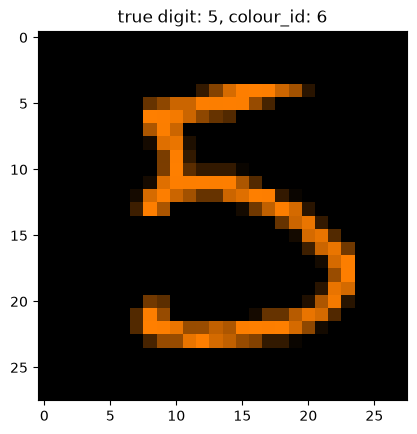

In [ ]:
# Selecting one image as an example
dataset = get_datasets(p=0.9)["test_conflicting"]
x = 5
y = 10
z = 15

img, label, colour_id = dataset[z]

plt.imshow(img.permute(1, 2, 0).numpy())
plt.title(f"true digit: {label.item()}, colour_id: {colour_id.item()}")
plt.show()


In [ ]:
# Getting the predicted and the true label for the image

logits = model(img.unsqueeze(0)) 
probs = F.softmax(logits, dim=1)[0] 

pred = logits.argmax().item()
print(f"predicted {pred}, true {label.item()}")


predicted 5, true 5


In [ ]:
# Use LIME to explain the model's prediction for the selected image

def predict_fn(batch):
    # batch: numpy (N, 28, 28, 3) -> tensor (N, 3, 28, 28)
    t = torch.from_numpy(batch).float().permute(0, 3, 1, 2)
    with torch.no_grad():
        return F.softmax(model(t), dim=1).numpy()   # numpy (N, 10)

img_np = img.permute(1, 2, 0).numpy().astype("double")   # (28, 28, 3)

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    img_np, predict_fn, top_labels=5, hide_color=0, num_samples=1000
)

100%|██████████| 1000/1000 [00:00<00:00, 1870.14it/s]


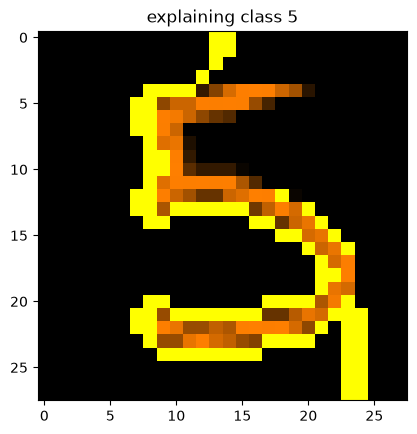

In [ ]:
# Visualize the explanation for the top predicted class

top_label = explanation.top_labels[0]
temp, mask = explanation.get_image_and_mask(
    top_label, positive_only=True, num_features=5, hide_rest=False
)
plt.imshow(mark_boundaries(temp, mask))
plt.title(f"explaining class {top_label}")
plt.show()

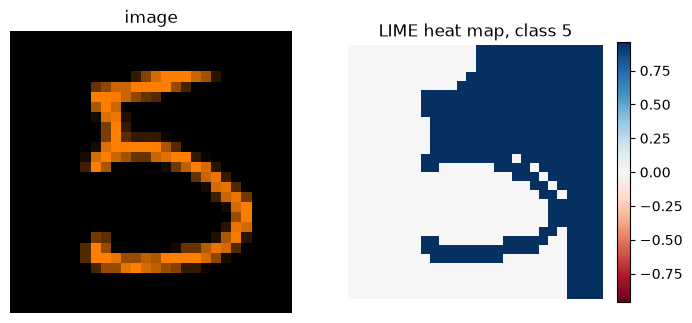

In [ ]:
# Use the explanation to create a heatmap for the top predicted class

label = explanation.top_labels[0]          # or colour_id.item() to explain the colour class

# superpixel id -> weight for this class
weights = dict(explanation.local_exp[label])
segments = explanation.segments            # (28, 28) array of superpixel ids

heatmap = np.zeros(segments.shape)
for seg_id, w in weights.items():
    heatmap[segments == seg_id] = w

m = np.abs(heatmap).max()
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_np.astype("float"))
axes[0].set_title("image")
im = axes[1].imshow(heatmap, cmap="RdBu", vmin=-m, vmax=m)
axes[1].set_title(f"LIME heat map, class {label}")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()